## Breast Cancer Classification Using a Decision Tree

This project uses a Decision Tree classifier to distinguish between benign and malignant cases. The model is first trained using specified parameters and then optimized using cross-validation. Its performance is evaluated using accuracy scores and a confusion matrix.

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

## Task 1: Load and Prepare the Data

The training and testing datasets are loaded separately. The X0-X8 columns contain the attributes that the model will use to make predictions, while the y column contains the class label (benign or malignant).

The attributes and class labels are separated so they can be used to train and test the model.

In [33]:
trn = pd.read_csv('/content/drive/MyDrive/data/BreastCancer_trn.csv')
tst = pd.read_csv('/content/drive/MyDrive/data/BreastCancer_tst.csv')

In [34]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import ConfusionMatrixDisplay

In [36]:
trn.head()

,X0,X1,X2,X3,X4,X5,X6,X7,X8,y
0,3,1,1,1,3,2,1,1,1,benign
1,5,1,3,1,2,1,2,1,1,benign
2,7,5,6,10,4,10,5,3,1,malignant
3,1,1,1,3,1,3,1,1,1,benign
4,2,1,1,1,3,1,2,1,1,benign


In [37]:
X_train = trn.drop(columns=['y'])
y_train = trn['y']

X_test = tst.drop(columns=['y'])
y_test = tst['y']

In [38]:
X_trn.head()

,X0,X1,X2,X3,X4,X5,X6,X7,X8
0,3,1,1,1,3,2,1,1,1
1,5,1,3,1,2,1,2,1,1
2,7,5,6,10,4,10,5,3,1
3,1,1,1,3,1,3,1,1,1
4,2,1,1,1,3,1,2,1,1


In [39]:
y_trn.head()

,y
0,benign
1,benign
2,malignant
3,benign
4,benign


## Task 2: Train the Initial Decision Tree

A Decision Tree classifier is trained on the training data using entropy as the criterion and a maximum of 7 leaf nodes. The criterion determines how the tree evaluates possible splits, while max_leaf_nodes limits the size of the tree.

This gives us an initial, non-optimized model that can later be compared with the optimized model.

In [40]:
dt = DecisionTreeClassifier(
    criterion='entropy',
    max_leaf_nodes=7,
    random_state=0
)

dt.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_leaf_nodes=7, random_state=0)

## Task 3: Optimize the Decision Tree

Instead of manually choosing the Decision Tree parameters, GridSearchCV is used to test different combinations of criterion and max_leaf_nodes.

The search compares entropy and gini while testing different maximum numbers of leaf nodes from 6 to 44. Five-fold cross-validation is used to evaluate the parameter combinations and determine which combination performs best.

In [41]:
parameters = {
    'criterion': ['entropy', 'gini'],
    'max_leaf_nodes': range(6, 45, 2)
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=1),
    parameters
)

grid.fit(X_train, y_train)

GridSearchCV(estimator=DecisionTreeClassifier(random_state=1),
             param_grid={'criterion': ['entropy', 'gini'],
                         'max_leaf_nodes': range(6, 45, 2)})

The best-performing model found by GridSearchCV is stored as `best_dt`. Displaying its parameters allows us to see which criterion and number of leaf nodes produced the best cross-validation performance.

In [42]:
best_dt = grid.best_estimator_
best_dt.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': 8,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 1,
 'splitter': 'best'}

## Task 4: Compare Parameter Accuracy

The cross-validation results from GridSearchCV are plotted to show how model accuracy changes as the maximum number of leaf nodes changes.

Separate lines are used for entropy and gini. This makes it possible to visually compare the two criteria and see which parameter combination achieved the highest cross-validation accuracy.

The dashed vertical line marks 8 leaf nodes, which was the value selected for the optimized model.

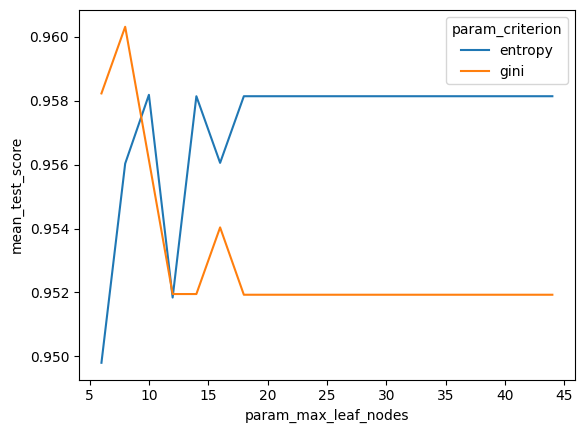

In [43]:
results = pd.DataFrame(grid.cv_results_)

for criterion in ['entropy', 'gini']:
    subset = results[results['param_criterion'] == criterion]
    plt.plot(
        subset['param_max_leaf_nodes'],
        subset['mean_test_score'],
        label=criterion
    )

plt.xlabel('param_max_leaf_nodes')
plt.ylabel('mean_test_score')
plt.legend(title='param_criterion')
plt.show()

## Task 5: Visualize the Optimized Decision Tree

The optimized Decision Tree is displayed so that its learned decision-making process can be examined visually. Each node shows a decision rule and information about the samples reaching that point in the tree.

The filled nodes help distinguish between the benign and malignant classes. The displayed depth is limited to make the tree easier to read.

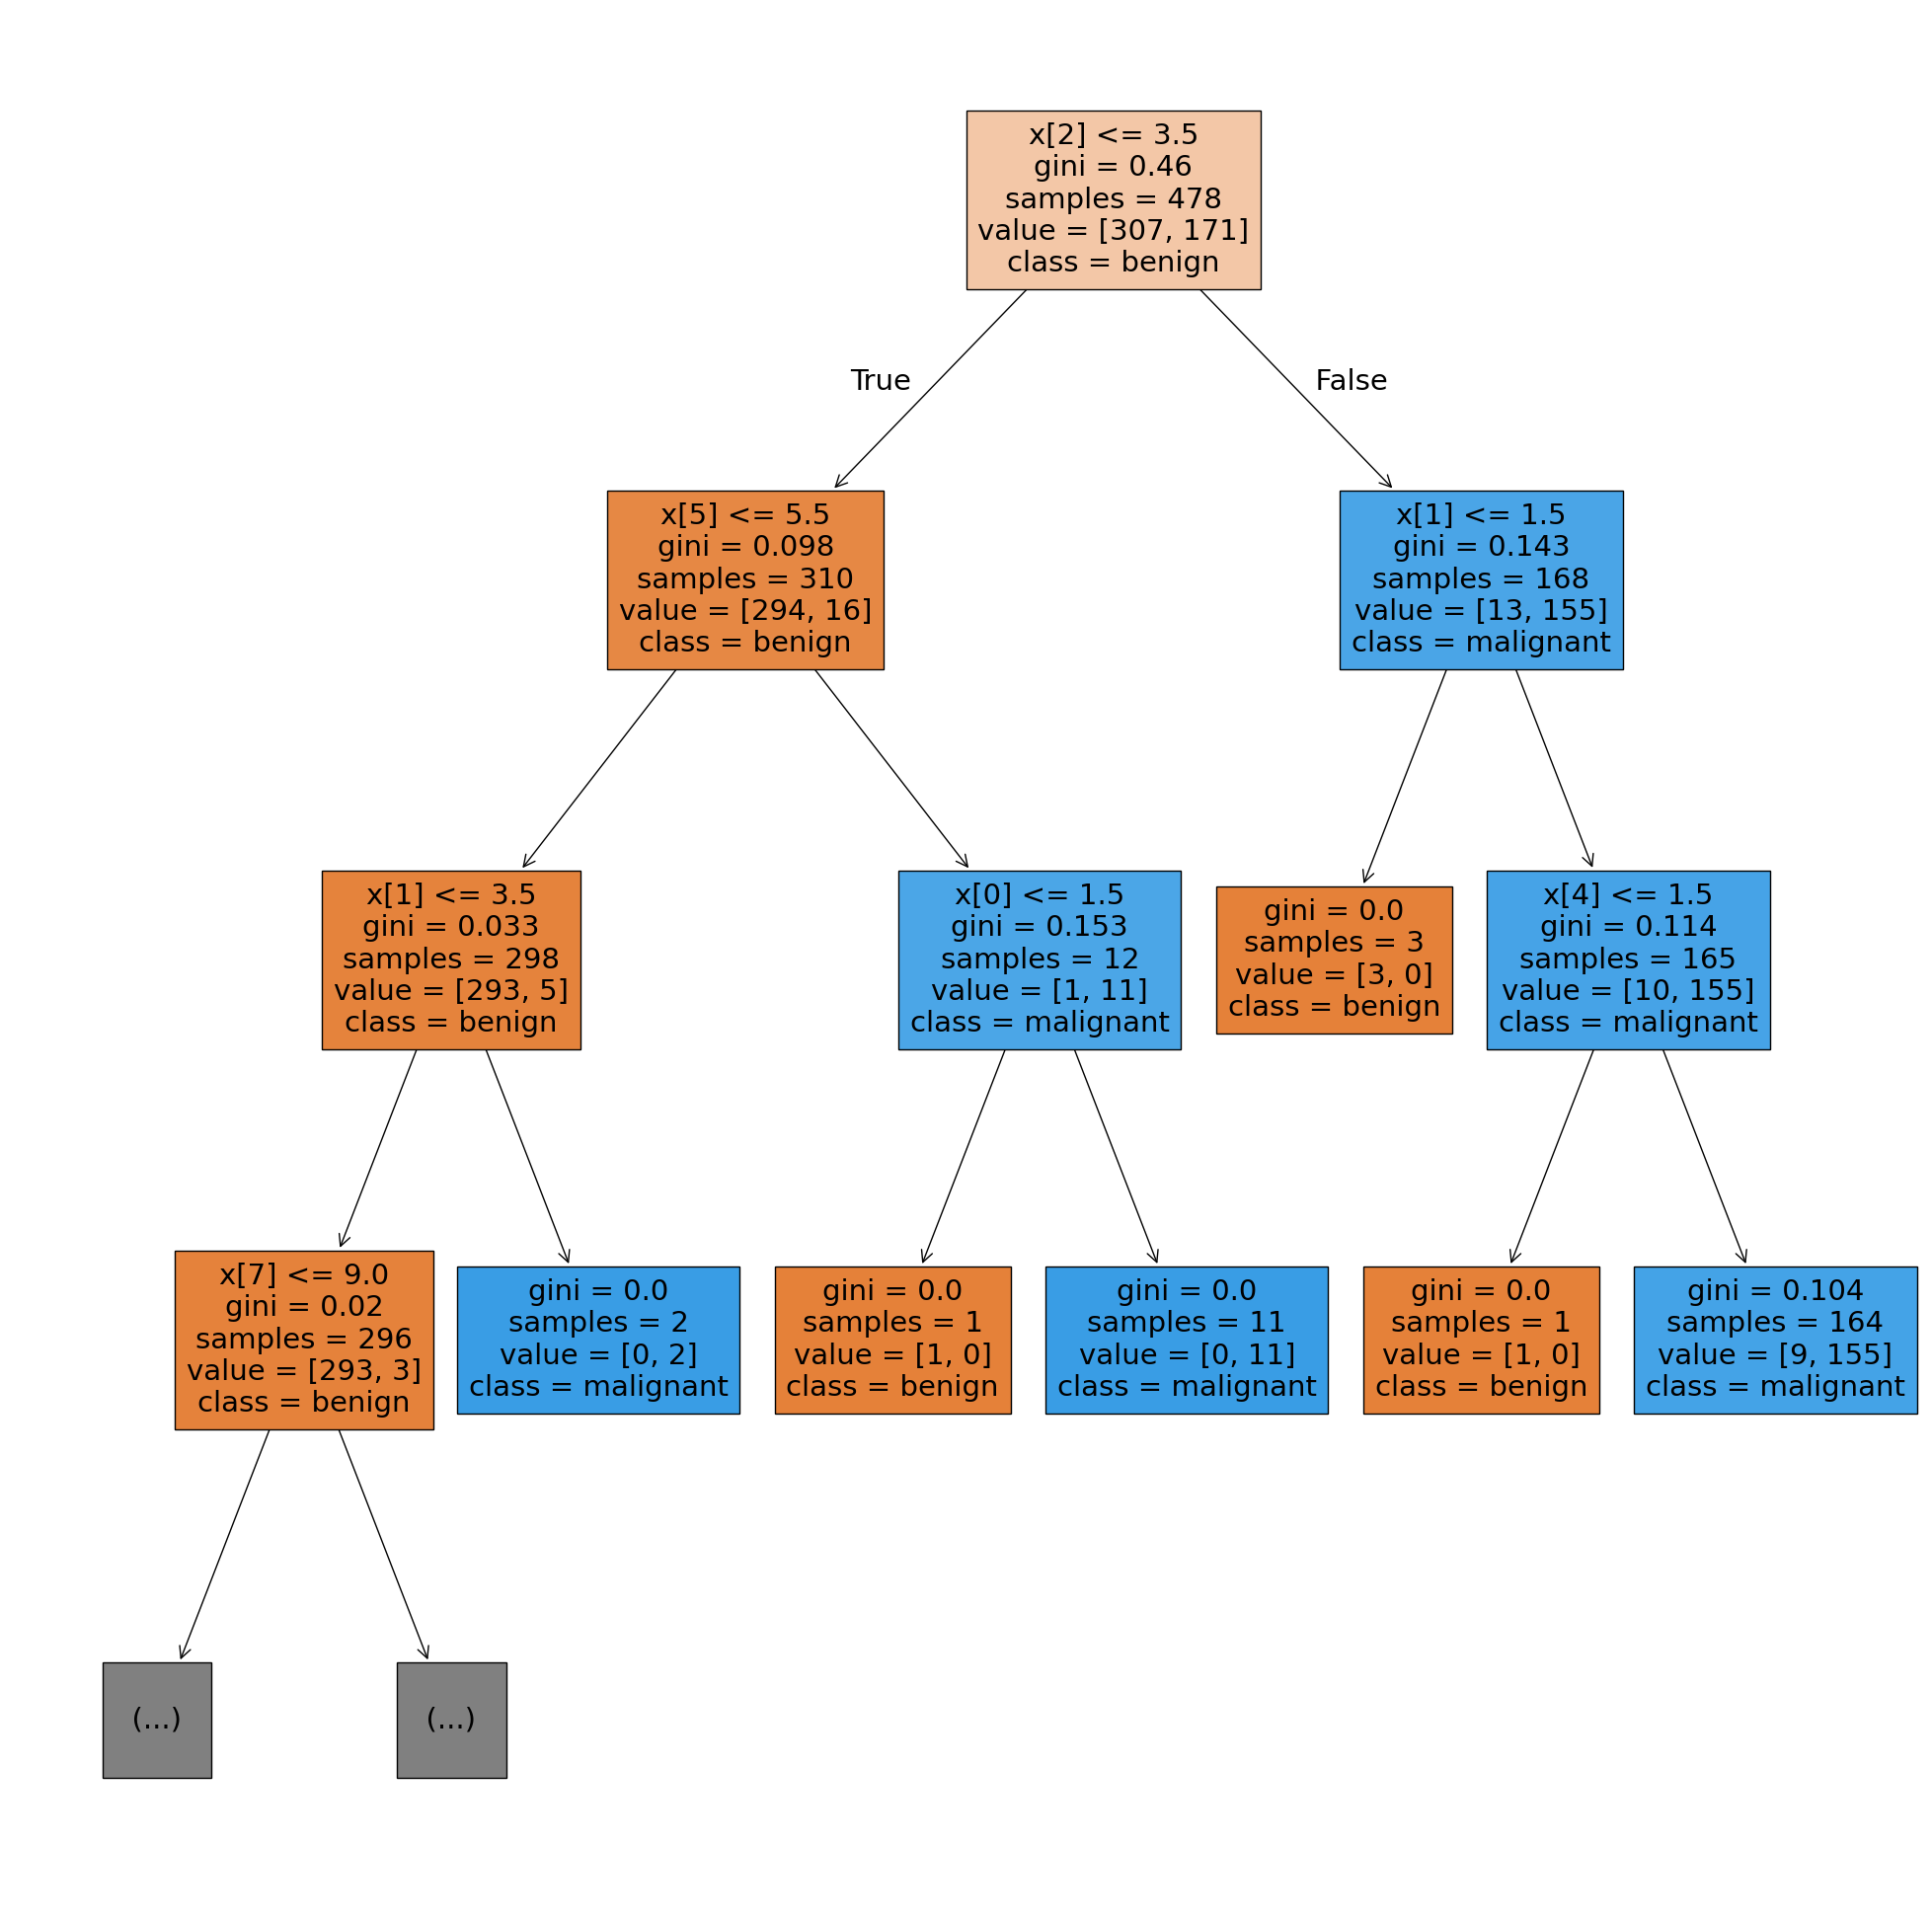

In [44]:
fig = plt.figure(figsize=(25, 25))

t = plot_tree(
    best_dt,
    class_names=['benign', 'malignant'],
    max_depth=3,
    filled=True
)

## Task 6: Evaluate the Model with a Confusion Matrix

The optimized model is evaluated on the testing dataset using a confusion matrix. The matrix compares the model's predicted labels with the actual labels.

The values are normalized across each row, so they represent proportions rather than raw counts. Values along the main diagonal represent correct classifications, while the off-diagonal values represent incorrect classifications.

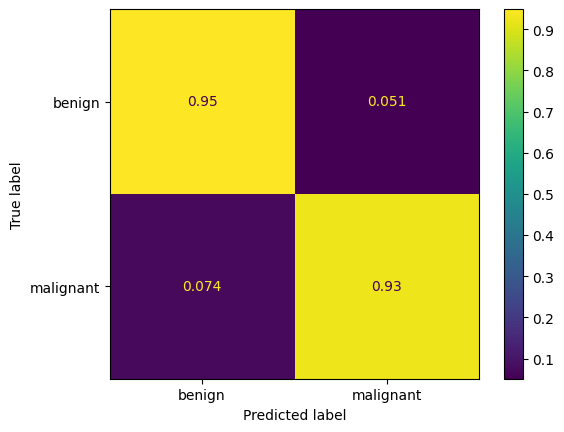

In [45]:
ConfusionMatrixDisplay.from_estimator(
    best_dt,
    X_test,
    y_test,
    normalize='true'
)

plt.show()

## Task 7: Calculate Overall Accuracy

Finally, the accuracy of both models is calculated. The training accuracy is measured using the original, non-optimized Decision Tree, while the testing accuracy is measured using the optimized Decision Tree.

The testing accuracy provides an indication of how well the optimized model performs on data that was not used to train it.

In [46]:
print(
    'Accuracy on training data: '
    + str("{:.2%}".format(dt.score(X_train, y_train)))
)

print(
    'Accuracy on testing data: '
    + str("{:.2%}".format(best_dt.score(X_test, y_test)))
)

Accuracy on training data: 97.91%
Accuracy on testing data: 94.15%
